# **At the moment, I just going to use the Perceptron of Scikit-learn to see how it's works and classify the data**

In [1]:
from sklearn.linear_model import Perceptron
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv('placement.csv')
df

,cgpa,resume_score,placed
0,8.14,6.52,1
1,6.17,5.17,0
2,8.27,8.86,1
3,6.88,7.27,1
4,7.52,7.30,1
...,...,...,...
95,6.33,6.38,0
96,8.23,7.76,1
97,6.65,7.78,0
98,8.14,5.63,1


<Axes: xlabel='cgpa', ylabel='resume_score'>

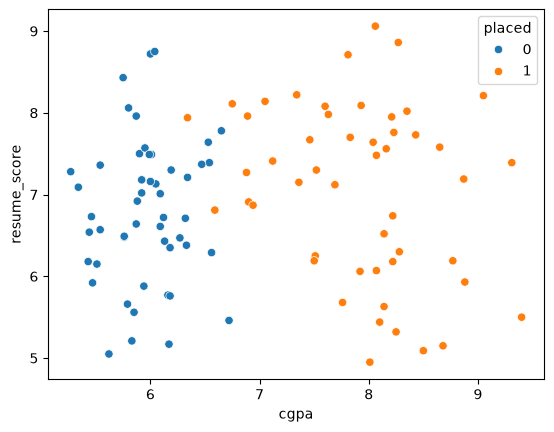

In [ ]:
sns.scatterplot(x = df['cgpa'],y = df['resume_score'],hue=df['placed'])

In [ ]:
X = df.iloc[:, 0:2]
y = df.iloc[:,-1]
print(X.head())

   cgpa  resume_score
0  8.14          6.52
1  6.17          5.17
2  8.27          8.86
3  6.88          7.27
4  7.52          7.30


In [ ]:
print(y.head())

0    1
1    0
2    1
3    1
4    1
Name: placed, dtype: int64


In [ ]:
perceptron = Perceptron()

In [ ]:
perceptron.fit(X,y)

,"penalty penalty: {'l2','l1','elasticnet'}, default=NoneThe penalty (aka regularization term) to be used.",None
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term if regularization isused.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with `0 <= l1_ratio <= 1`.`l1_ratio=0` corresponds to L2 penalty, `l1_ratio=1` to L1.Only used if `penalty='elasticnet'`... versionadded:: 0.24",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, the iterations will stopwhen (loss > previous_loss - tol)... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.",0
,"eta0 eta0: float, default=1Constant by which the updates are multiplied.",1.0
,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"random_state random_state: int, RandomState instance or None, default=0Used to shuffle the training data, when ``shuffle`` is set to``True``. Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",0


In [ ]:
perceptron.coef_

array([[ 40.26, -36.  ]])

In [ ]:
perceptron.intercept_

array([-25.])

<Axes: >

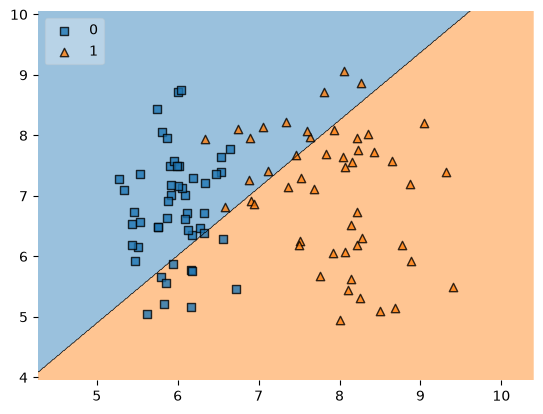

In [ ]:
from mlxtend.plotting import plot_decision_regions

plot_decision_regions(X.values, y.values, clf=perceptron, legend=2)

**Though it is not a good result, today I just want to see how a Percep**

# **Going to Classify the regions without using Perceptron class just by updating and finding the best coeff. and y_intercept**

In [ ]:
def step(z):
  return 1 if z > 0 else 0

In [ ]:
def Perceptron(X, y, lr = 0.1, epochs = 1000):

  X = np.asarray(X)

  coeff_       = np.ones(X.shape[1])
  y_intercept_ = 1
  lr           = 0.1

  for i in range(epochs):

    j = np.random.randint(X.shape[0])
    prediction = step(np.dot(X[j], coeff_) + y_intercept_)

    if prediction != y[j]:
      coeff_        += lr * (y[j] - prediction) * X[j]
      y_intercept_  += lr * (y[j] - prediction)

  return coeff_, y_intercept_


In [ ]:
coeff_, y_intercept_ = Perceptron(X, y, lr = 0.3, epochs = 100000)

In [ ]:
print(coeff_)
print(y_intercept_)

[9.134 0.619]
-64.90000000000059


(4.75, 9.26)

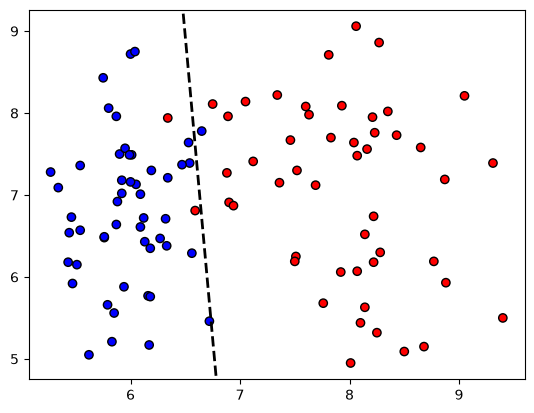

In [ ]:
w1, w2 = coeff_[0], coeff_[1]
b = y_intercept_

slope = -(w1 / w2)
intercept = -(b / w2)


plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=y, cmap='bwr', edgecolor='k', label='Data Points')


x_min, x_max = X.iloc[:, 0].min() - 1, X.iloc[:, 0].max() + 1

x_values = np.linspace(x_min, x_max, 100)
y_values = slope * x_values + intercept

plt.plot(x_values, y_values, color='black', linestyle='--', linewidth=2, label='Perceptron Boundary')
plt.xlim(X.iloc[:, 0].min() - 0.2, X.iloc[:, 0].max() + 0.2)
plt.ylim(X.iloc[:, 1].min() - 0.2, X.iloc[:, 1].max() + 0.2)


**Perceptron is not working well because the data is non-linear kind**

**After a little param tuning, I got a good result**

**Let's Make a linear classification dataset and try our Perceptron on it**

In [ ]:
from sklearn.datasets import make_classification
X, y = make_classification(n_samples=100, n_features=2, n_informative=1,n_redundant=0,
                           n_classes=2, n_clusters_per_class=1, random_state=41,hypercube=False,class_sep=10)

In [ ]:
coeff_, y_intercept_ = Perceptron(X, y, lr = 0.01, epochs=1000)

In [ ]:
w1, w2 = coeff_[0], coeff_[1]
b = y_intercept_

In [ ]:
slope = -(w1 / w2)
intercept = -(b / w2)

(-3.180924316139516, 2.2615874036005192)

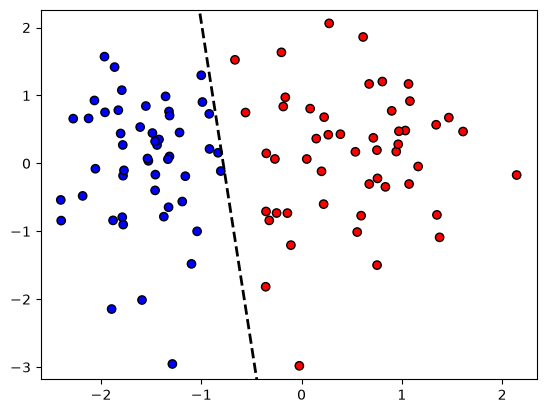

In [ ]:
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='bwr', edgecolor='k', label='Data Points')


x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1

x_values = np.linspace(x_min, x_max, 100)
y_values = slope * x_values + intercept

plt.plot(x_values, y_values, color='black', linestyle='--', linewidth=2, label='Perceptron Boundary')
plt.xlim(X[:, 0].min() - 0.2, X[:, 0].max() + 0.2)
plt.ylim(X[:, 1].min() - 0.2, X[:, 1].max() + 0.2)

# **Now test the self made perceptron class on a 3 features dataset**

In [7]:
from perceptron import Perceptron
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

X, y = make_classification(n_samples=1000, n_features=3, n_informative=1,n_redundant=0,
                           n_classes=2, n_clusters_per_class=1, random_state=41,hypercube=False,class_sep=10)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [8]:
X_train

array([[ 0.63539763,  1.13530976, -2.62003642],
       [-0.95712823,  1.45208738, -2.40713307],
       [ 1.43506634,  0.08867478,  0.27845286],
       ...,
       [ 1.76570218,  0.45427989, -1.55795595],
       [-0.60159568,  1.65235033, -1.57265436],
       [ 0.06414626,  0.59061453, -1.86069642]])

**first see how it classify the training data**

In [11]:
import plotly.express as px

figure = px.scatter_3d(x=X_train[:, 0], y=X_train[:, 1], z=X_train[:,2], color=y_train,opacity=0.7,labels={"x": "Feature 1", "y": "Feature 2", "z": "Feature 3"})
figure.update_layout(legend=dict(x=0, y=1))
figure.show()

In [12]:
custom_perceptron = Perceptron(learning_rate=0.1, epochs=1000)
coeff_ , y_intercept = custom_perceptron.fit(X_train, y_train)

In [18]:
coeff_, y_intercept

(array([-0.04637932,  0.0982568 ,  0.58183068]),
 np.float64(0.10000000000000003))

In [23]:
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

x_values = np.linspace(x_min, x_max, 50)
y_values = np.linspace(y_min, y_max, 50)
X_grid, Y_grid = np.meshgrid(x_values, y_values)

In [24]:
w1 = coeff_[0]
w2 = coeff_[1]
w3 = coeff_[2]
b  = y_intercept


Z_grid = (-w1 * X_grid - w2 * Y_grid - b) / w3

In [27]:
import plotly.graph_objects as go

fig = px.scatter_3d(x=X[:, 0], y=X[:, 1], z=X[:, 2], color=y,  labels={"x": "Feature 1", "y": "Feature 2", "z": "Feature 3"})

fig.add_trace(
    go.Surface(
        x=X_grid,
        y=Y_grid,
        z=Z_grid,
        colorscale="Viridis",
        opacity=0.6,
        showscale=False
    )
)

fig.show()

**Perceptron classifying the data quite nicely. Now, check it's performance on unseen data**

In [28]:
pred = custom_perceptron.predict(X_test)
pred

array([1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0,
       1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0,
       1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0,
       1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0,
       1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0,
       1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0,
       1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0,
       1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1,
       1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1,
       0, 1])

In [29]:
from sklearn.metrics import accuracy_score

acc = accuracy_score(y_test, pred)
print(acc)

0.965


**So Perceptron is classifying the data very well**

# **Conclusion**

 So, I learned the core concept of perceptron and find out how perceptron works and how it classify the Binary data. Indeed, Perceptron works only for Linear or kind of Linear datasets but it's the fundamental unit of Neural Networks and necessary to for the study of Deep learning, I made custom Perceptron and it was working well for a linear sort of dataset